# 데이터 점검: VisA와 Real-IAD

2단계(Q1)에 들어가기 전에 Drive에 있는 데이터가 읽기 코드와 맞는지 본다. 학습은 하지 않고 GPU도 필요 없다. 이 레포 코드의 Real-IAD 읽기는 가짜 파일로만 시험했으므로, **실제 JSON과 zip을 처음 읽는 자리가 여기다.**

여기서 정해지는 것:
- Real-IAD의 C1이 위 시점인가
- Real-IAD에서 쓸 부류(`configs/experiments.yaml`의 `real_iad.categories`)
- 각 데이터의 이미지 해상도(`data/README.md`에 적는다)

In [1]:
import glob, json, os, subprocess, sys, zipfile
from collections import Counter
from io import BytesIO

REPO_DIR = "/content/beyond-mvtec"
if not os.path.isdir(REPO_DIR):
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    subprocess.run(["git", "clone", "-q", f"https://{token}@github.com/chlee1027/beyond-mvtec.git", REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", "https://github.com/chlee1027/beyond-mvtec.git"], check=True)
sys.path.insert(0, os.path.join(REPO_DIR, "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from PIL import Image
from beyond_mvtec import data

drive.mount("/content/drive")
MY = "/content/drive/MyDrive"

Mounted at /content/drive


## VisA

In [2]:
VISA = next(p for p in [f"{MY}/visa", f"{MY}/VisA_20220922", f"{MY}/VisA"] if os.path.isfile(f"{p}/split_csv/1cls.csv"))
rows = []
for category in data.visa_categories(VISA):
    split = data.list_visa(VISA, category)
    sizes = Counter(Image.open(p).size for p in split.train[:20])
    anomaly = next(s for s in split.test if s.label == 1)
    mask = Image.open(anomaly.mask)
    rows.append({"category": category, "train": len(split.train), "test": len(split.test),
                 "test_anomaly": sum(s.label for s in split.test), "size_wh": sizes.most_common(1)[0][0],
                 "mask_mode": mask.mode, "mask_values": np.unique(np.asarray(mask))[:5].tolist()})
visa_table = pd.DataFrame(rows)
display(visa_table)
print("부류", len(visa_table), "| 학습", visa_table["train"].sum(), "| 시험", visa_table["test"].sum())

,category,train,test,test_anomaly,size_wh,mask_mode,mask_values
0,candle,900,200,100,"(1284, 1168)",L,"[0, 1]"
1,capsules,542,160,100,"(1500, 1000)",L,"[0, 1]"
2,cashew,450,150,100,"(1274, 1176)",L,"[0, 1, 2]"
3,chewinggum,453,150,100,"(1342, 1118)",L,"[0, 1, 3, 5]"
4,fryum,450,150,100,"(1500, 1000)",L,"[0, 1]"
5,macaroni1,900,200,100,"(1500, 1000)",L,"[0, 1]"
6,macaroni2,900,200,100,"(1500, 1000)",L,"[0, 1, 6]"
7,pcb1,904,200,100,"(1404, 1070)",L,"[0, 1]"
8,pcb2,901,200,100,"(1404, 1070)",L,"[0, 1]"
9,pcb3,905,201,100,"(1562, 960)",L,"[0, 1]"


부류 12 | 학습 8659 | 시험 2162


## Real-IAD: zip과 JSON

In [3]:
REALIAD_DIR = f"{MY}/Real_IAD"
JSON_ZIP = f"{MY}/realiad_jsons.zip"
LOCAL = "/content/data/real_iad"
os.makedirs(LOCAL, exist_ok=True)

zips = sorted(glob.glob(f"{REALIAD_DIR}/*.zip"))
print("부류 zip", len(zips), "개:", [os.path.splitext(os.path.basename(z))[0] for z in zips])
print("JSON zip 있음:", os.path.isfile(JSON_ZIP))
if not os.path.isdir(f"{LOCAL}/realiad_jsons"):
    with zipfile.ZipFile(JSON_ZIP) as z:
        z.extractall(f"{LOCAL}/realiad_jsons")

folders = Counter(os.path.basename(os.path.dirname(p)) for p in glob.glob(f"{LOCAL}/realiad_jsons/**/*.json", recursive=True))
print("JSON 폴더별 파일 수:", dict(folders))

# 항목의 실제 모양을 본다. 읽기 코드는 anomaly_class, image_path, mask_path 를 가정한다
category = os.path.splitext(os.path.basename(zips[0]))[0]
path = data._find_real_iad_json(f"{LOCAL}/realiad_jsons", category)
meta = json.load(open(path, encoding="utf-8"))
print("고른 JSON:", path)
print("meta:", meta.get("meta"))
print("train[0]:", meta["train"][0])
print("test[0]:", meta["test"][0])
print("이상 항목 하나:", next((e for e in meta["test"] if str(e.get("anomaly_class", "")).upper() != "OK"), None))

부류 zip 30 개: ['audiojack', 'bottle_cap', 'button_battery', 'end_cap', 'eraser', 'fire_hood', 'mint', 'mounts', 'pcb', 'phone_battery', 'plastic_nut', 'plastic_plug', 'porcelain_doll', 'regulator', 'rolled_strip_base', 'sim_card_set', 'switch', 'tape', 'terminalblock', 'toothbrush', 'toy', 'toy_brick', 'transistor1', 'u_block', 'usb', 'usb_adaptor', 'vcpill', 'wooden_beads', 'woodstick', 'zipper']
JSON zip 있음: True
JSON 폴더별 파일 수: {'realiad_jsons_fuiad_0.2': 30, 'realiad_jsons_fuiad_0.4': 30, 'realiad_jsons_sv': 30, 'realiad_jsons_fuiad_0.0': 30, 'realiad_jsons': 30, 'realiad_jsons_fuiad_0.1': 30}
고른 JSON: /content/data/real_iad/realiad_jsons/realiad_jsons/audiojack.json
meta: {'prefix': 'audiojack/', 'normal_class': 'OK', 'pre_transform': False}
train[0]: {'category': 'audiojack', 'anomaly_class': 'OK', 'image_path': 'OK/S0004/audiojack_0004_OK_C1_20231021130716.jpg', 'mask_path': None}
test[0]: {'category': 'audiojack', 'anomaly_class': 'OK', 'image_path': 'OK/S0001/audiojack_0001_OK_C

## Real-IAD: C1이 위 시점인가

같은 표본의 다섯 시점을 나란히 그린다. C1이 위에서 찍은 사진이 아니면 `views`를 고쳐야 한다.

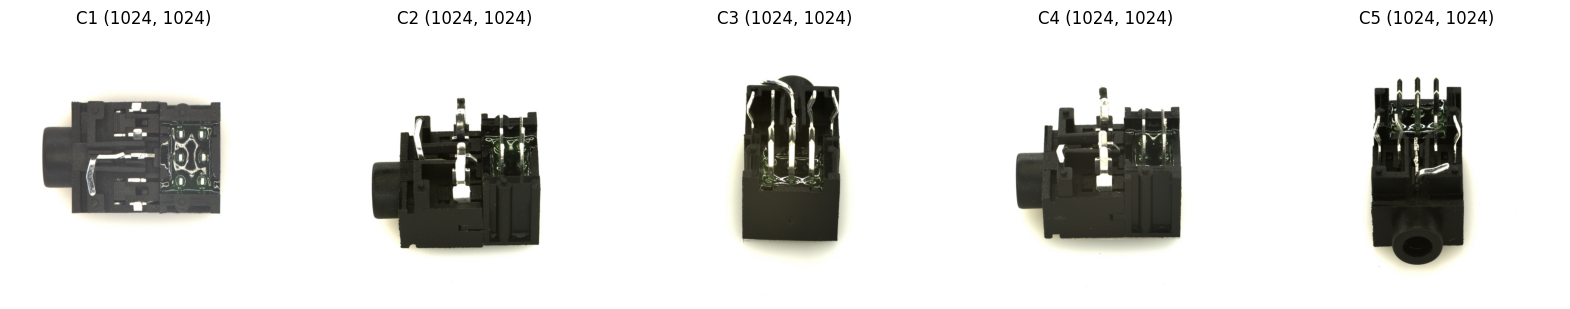

이미지 수 5050 | 시점별 {'C1': 1010, 'C2': 1010, 'C3': 1010, 'C4': 1010, 'C5': 1010}
예: audiojack/NG/BX/S0001/audiojack__0001_NG_BX_C1_20231023111538.jpg


In [4]:
with zipfile.ZipFile(zips[0]) as z:
    names = [n for n in z.namelist() if n.lower().endswith((".jpg", ".jpeg"))]
    first = next(n for n in names if data.view_of(n) == "C1")
    sample_dir = os.path.dirname(first)
    views = sorted((data.view_of(n), n) for n in names if os.path.dirname(n) == sample_dir and data.view_of(n))
    fig, axes = plt.subplots(1, len(views), figsize=(4 * len(views), 4))
    for ax, (view, name) in zip(np.atleast_1d(axes), views):
        image = Image.open(BytesIO(z.read(name)))
        ax.imshow(image); ax.set_title(f"{view} {image.size}"); ax.axis("off")
    plt.show()
print("이미지 수", len(names), "| 시점별", dict(Counter(data.view_of(n) for n in names)))
print("예:", first)

## Real-IAD: 부류마다 C1만 풀어 읽기

In [5]:
rows = []
for zip_path in zips:
    category = os.path.splitext(os.path.basename(zip_path))[0]
    data.prepare_real_iad(zip_path, LOCAL, category, view="C1")
    split = data.list_real_iad(LOCAL, category, view="C1")  # 파일이 빠졌으면 여기서 오류가 난다
    anomaly = [s for s in split.test if s.label == 1]
    sv_path = glob.glob(f"{LOCAL}/realiad_jsons/**/realiad_jsons_sv/{category}.json", recursive=True)
    sv = json.load(open(sv_path[0], encoding="utf-8")) if sv_path else {"train": [], "test": []}
    rows.append({"category": category, "train": len(split.train), "test": len(split.test),
                 "test_anomaly": len(anomaly), "mask_found": sum(s.mask is not None for s in anomaly),
                 "size_wh": Image.open(split.train[0]).size,
                 "sv_train": len(sv["train"]), "sv_test": len(sv["test"])})
real_table = pd.DataFrame(rows)
display(real_table)

,category,train,test,test_anomaly,mask_found,size_wh,sv_train,sv_test
0,audiojack,247,763,213,213,"(1024, 1024)",399,611
1,bottle_cap,246,757,264,264,"(1024, 1024)",370,633
2,button_battery,242,758,417,417,"(1024, 1024)",292,708
3,end_cap,241,761,424,424,"(1024, 1024)",289,713
4,eraser,246,767,235,235,"(1024, 1024)",389,624
5,fire_hood,251,754,169,169,"(1024, 1024)",418,587
6,mint,167,894,450,450,"(1024, 1024)",306,755
7,mounts,250,760,240,240,"(1024, 1024)",385,625
8,pcb,247,755,445,445,"(1024, 1024)",279,723
9,phone_battery,242,758,301,301,"(1024, 1024)",350,650


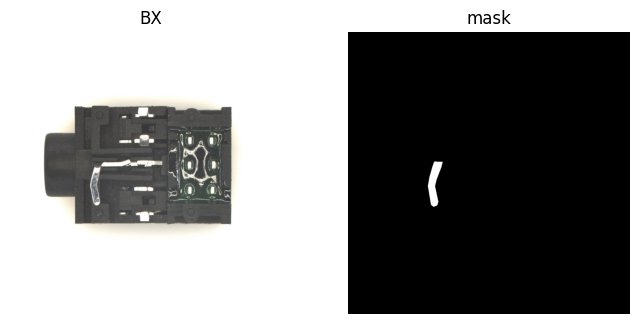

In [6]:
# 결함이 든 이미지 하나를 마스크와 함께 그려 짝이 맞는지 눈으로 본다
split = data.list_real_iad(LOCAL, real_table.loc[0, "category"], view="C1")
anomaly = next(s for s in split.test if s.label == 1)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(anomaly.image)); axes[0].set_title(anomaly.anomaly); axes[0].axis("off")
axes[1].imshow(np.asarray(Image.open(anomaly.mask)) > 0, cmap="gray"); axes[1].set_title("mask"); axes[1].axis("off")
plt.show()